## Google Colab setup

Set `REPO_URL`, `BRANCH`, `RUN_NAME` and `BASE` in the next cell. Open this notebook from the same GitHub branch. The setup mounts Drive, clones code into the runtime and installs dependencies; local execution skips it. Use a fresh runtime after pushing new code. All notebooks in one experiment use the same run name; choose a new name for a fresh experiment. Run preprocessing and feature engineering to completion before model notebooks. The repository README describes the dataset layout and execution order.

In [1]:
# Configure this cell before running on Google Colab.
import os
import sys
import subprocess
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    REPO_URL = "https://github.com/nguyenvanminh281005/bt4222-group12.git"
    BRANCH = "refactor-final"
    RUN_NAME = "run_01"
    BASE = Path("/content/drive/MyDrive/BT4222 - Group 12")
    CHECKOUT = Path("/content/bt4222_checkout")
    drive.mount("/content/drive")
    if not CHECKOUT.exists():
        subprocess.run([
            "git", "clone", "--branch", BRANCH, "--single-branch",
            REPO_URL, str(CHECKOUT)
        ], check=True)
    active_branch = subprocess.check_output(
        ["git", "-C", str(CHECKOUT), "branch", "--show-current"], text=True
    ).strip()
    if active_branch != BRANCH:
        raise ValueError("Checkout branch differs from BRANCH. Use a fresh Colab runtime.")
    CODE_DIR = (CHECKOUT if (CHECKOUT / "utils/data_utils.py").is_file()
                else CHECKOUT / "bt4222-group12")
    if not (CODE_DIR / "utils/data_utils.py").is_file():
        raise FileNotFoundError("The selected branch does not contain the Group 12 project.")
    os.environ.update({
        "BT4222_BASE": str(BASE),
        "MIND_DATA_DIR": str(BASE / "data"),
        "BT4222_PROCESSED_DIR": str(BASE / "processed"),
        "BT4222_FEATURE_DIR": str(BASE / "features"),
        "BT4222_GLOVE_PATH": str(BASE / "data/glove/glove.6B.300d.txt"),
        "BT4222_OUTPUT_DIR": str(BASE / "runs" / RUN_NAME),
    })
    os.chdir(CODE_DIR)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-r", "requirements.txt"
    ], check=True)
    print("Code:", CODE_DIR)
    print("Features:", os.environ["BT4222_FEATURE_DIR"])
    print("Run outputs:", os.environ["BT4222_OUTPUT_DIR"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Code: /content/bt4222_checkout
Features: /content/drive/MyDrive/BT4222 - Group 12/features
Run outputs: /content/drive/MyDrive/BT4222 - Group 12/runs/run_01


# MLP Ranker: Staged Development

Each stage fixes the weakness found in the previous stage's **validation** results.

| Stage | Model | Change | Saved runs reused |
|---|---|---|---|
| 1 | Initial MLP | Fixes the past project's design gaps: five feature blocks, LayerNorm, listwise loss | `mlp/initial/ablation_runs/` |
| 2 | Improved MLP | Adds cold-user simulation (15% of users with history shown as cold in each training batch) | `mlp/improved/ablation_runs/` |
| 3 | Attention MLP | Adds candidate-conditioned attention over the last 50 clicks | `mlp/attention/runs/` |
| 4 | Final model | Selects the best model on validation, then evaluates **only that model** on test | — |

**Validation-only rule.** Stages 1–3 report validation (14 Nov) results only. Every diagnosis and every model choice uses validation. The test day (15 Nov) is used once, in Stage 4, for the selected model, so it stays an unbiased final check.

**Saved runs.** Each training run is saved with its exact settings. If a run with identical settings exists, it is reloaded instead of retrained. New tables, figures and predictions are written to `mlp/staged/`.

**Ranking objective.** For a candidate group with clicked set $P$ and candidates $C$,

$$\mathcal L=-\frac{1}{|P|}\sum_{i\in P}\log\frac{\exp(s_i)}{\sum_{j\in C}\exp(s_j)}.$$

Masked padding contributes neither to the softmax denominator nor to evaluation. Training groups hold one click and up to four negatives from the same impression; validation and test keep the full slate.

In [2]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "utils" / "data_utils.py").is_file()
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.data_utils import project_paths, load_preprocessed, load_table, save_table

if os.environ.get("BT4222_USE_DRIVE") == "1":
    from google.colab import drive

    drive.mount("/content/drive")

PATHS = project_paths(PROJECT_ROOT)
from utils.data_utils import source_fingerprint, validate_features, bind_feature_run

feature_id = validate_features(PATHS)
bind_feature_run(PATHS, feature_id)

In [3]:
from utils.metrics import ndcg_at_k, history_groups

## 0. Shared setup
Everything in this section is shared by all stages: settings, features, metrics, the base model and the training loop.

In [4]:
import os, json, time, copy, random
import numpy as np
import pandas as pd
from scipy.stats import rankdata
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as Fnn
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

FEATURE_DIR = str(PATHS["features"])
MLP_OUT = PATHS["outputs"] / "mlp"
# Saved training runs are read from (and, if missing, written to) the original folders
RUN_DIRS = {
    "initial": str(MLP_OUT / "initial" / "ablation_runs"),
    "improved": str(MLP_OUT / "improved" / "ablation_runs"),
    "attention": str(MLP_OUT / "attention" / "runs"),
}
# New tables, figures and predictions from this notebook
REPORT_DIRS = {
    s: str(MLP_OUT / "staged" / s)
    for s in ["stage1_initial", "stage2_improved", "stage3_attention", "stage4_final"]
}
for d in list(RUN_DIRS.values()) + list(REPORT_DIRS.values()):
    os.makedirs(d, exist_ok=True)

MODEL_NAME = "mlp"
# ── Hyperparameters (shared by every stage) ─────────────────────────────────
SEED = 42
EMBED_DIM = 64
CAT_DIM = 32
SUBCAT_DIM = 32
HIDDEN = [128, 64, 32]
DROPOUT = 0.2
ID_DROPOUT = 0.1
LR = 1e-3
WEIGHT_DECAY = 1e-5
BATCH_SIZE = 32
EVAL_BATCH = 128  # impressions per evaluation batch (Stages 1-2)
MAX_EPOCHS = 8
PATIENCE = 2
SELECT_METRIC = "nDCG@5"  # early stopping and every model choice use validation nDCG@5
# ── Evaluation & export ──────────────────────────────────────────────────────
NDCG_KS = (5, 10)
RECALL_KS = (5, 10)
TOPK_EXPORT = 10
# ── Feature groups & optional features (the starting "full" model uses everything) ─
USE_GROUPS = {
    "article": True,
    "popularity": True,
    "user": True,
    "user_x_article": True,
    "context": True,
}
USE_OPTIONAL = {
    "diversity_ratio": True,
    "habit_score": True,
}  # features from the past project, kept or dropped by ablation
# ── Ablation & model selection (Stages 1 and 2) ─────────────────────────────
RUN_ABLATION = True
ABLATION_EPOCHS = MAX_EPOCHS
ABLATION_SEEDS = [SEED]  
DROP_TOLERANCE = 0.001  # drop a component if removing it changes val nDCG@5 by >= -0.001
# ── Stage 2: cold-user simulation ────────────────────────────────────────────
COLD_SIM_RATE = 0.15  # share of users with history shown as cold users in each training batch
COMPARE_NO_SIM = True  # also report the Stage 2 config trained WITHOUT simulation
# ── Stage 3: attention ──────────────────────────────────────────────────────
HIST_LEN = 50  # most recent clicks the attention looks at
ATT_HIDDEN = 32  # size of the network that scores each click
EVAL_ROWS = 8192  # candidates per evaluation batch for the attention model (memory)

SPLITS = ["train", "val", "test"]
SLICE_ORDER = ["all", "warm_user", "sparse_user", "cold_user", "cold_article"]
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
print("FEATURE_DIR =", FEATURE_DIR)
print("Saved runs  :", json.dumps(RUN_DIRS, indent=2))


def load_feature_table(name):
    base = os.path.join(FEATURE_DIR, name)
    return (
        pd.read_parquet(base + ".parquet")
        if os.path.exists(base + ".parquet")
        else pd.read_pickle(base + ".pkl")
    )


def save_output_table(df, name, out_dir):
    path = os.path.join(out_dir, name)
    try:
        df.to_parquet(path + ".parquet", index=False)
    except ImportError:
        df.to_pickle(path + ".pkl")

device: cpu
FEATURE_DIR = /content/drive/MyDrive/BT4222 - Group 12/features
Saved runs  : {
  "initial": "/content/drive/MyDrive/BT4222 - Group 12/runs/run_01/mlp/initial/ablation_runs",
  "improved": "/content/drive/MyDrive/BT4222 - Group 12/runs/run_01/mlp/improved/ablation_runs",
  "attention": "/content/drive/MyDrive/BT4222 - Group 12/runs/run_01/mlp/attention/runs"
}


### 0.1 Load engineered features

In [5]:
with open(os.path.join(FEATURE_DIR, "feature_meta.json")) as f:
    meta = json.load(f)

dims = meta["dims"]
N_ART, N_CAT, N_SUBCAT = dims["n_articles"], dims["n_cat"], dims["n_subcat"]
SPARSE_MAX = meta["cold_start"]["sparse_user_max"]
articles = load_feature_table("articles")
content_emb = np.load(os.path.join(FEATURE_DIR, "article_content_emb.npy")).astype(
    np.float32
)
kg_emb = np.load(os.path.join(FEATURE_DIR, "kg_entity_emb.npy")).astype(np.float32)
has_kg = np.zeros(N_ART, np.float32)
has_kg[articles.news_idx.values] = articles.has_kg_entity.values
art_cat = np.zeros(N_ART, np.int64)
art_cat[articles.news_idx.values] = articles.category_idx.values
art_subcat = np.zeros(N_ART, np.int64)
art_subcat[articles.news_idx.values] = articles.subcategory_idx.values
news_ids = np.empty(N_ART, dtype=object)
news_ids[0] = "<PAD>"
news_ids[articles.news_idx.values] = articles.news_id.values
profiles = (
    load_feature_table("user_profiles").sort_values("profile_idx").reset_index(drop=True)
)
user_emb = np.load(os.path.join(FEATURE_DIR, "user_history_emb.npy")).astype(np.float32)
user_aff = np.load(os.path.join(FEATURE_DIR, "user_category_affinity.npy")).astype(
    np.float32
)
data = {
    s: {
        "imp": load_feature_table(f"{s}/impressions"),
        "groups": load_feature_table(f"{s}/groups"),
        "cands": load_feature_table(f"{s}/candidates"),
    }
    for s in SPLITS
}

for s in SPLITS:
    print(
        f"{s:5s}: {len(data[s]['groups']):>8,} groups | {len(data[s]['cands']):>10,} candidates | "
        f"days {[int(x) for x in sorted(data[s]['imp'].day.unique())]}"
    )

print(
    "Split:",
    meta["split"]["scheme"],
    "| negatives:",
    meta["negative_sampling"]["train"],
)

train:  189,519 groups |    906,625 candidates | days [0, 1, 2, 3, 4]
val  :   30,270 groups |  1,222,429 candidates | days [5]
test :   73,152 groups |  2,740,998 candidates | days [6]
Split: 5-1-1 by calendar day | negatives: per positive, up to 4 negatives from same impression, no replacement, seed 42; short groups masked (no repeats); impressions without negatives dropped


### 0.2 Input preparation
The model inputs were prepared by the feature engineering notebook and are loaded here from `mlp_inputs.pkl`. The list of features in each group comes from `feature_meta.json`.

**Scaling.** Continuous features (e.g. `hist_ctr`, `cos_user_hist`) are standardised to mean 0 and standard deviation 1, using statistics from the **training days only**, so no information from validation or test leaks in. Binary flags (`is_cold_article`, `category_match`, `has_history`) are left as 0/1.

**How each split is stored.** Impressions have different numbers of candidates: training groups have at most 5 (one click and up to four negatives), while validation and test slates range from a few articles to about 300. Rather than one table padded to the longest slate, each split stores:
* **flat arrays** with one row per candidate, all impressions placed back to back (`news`, `label`, `cand_x`, ...);
* **two offset arrays** that say where each impression sits: `start[g]` is the row where impression `g` begins and `n[g]` is how many candidates it has.

For example, three impressions with 3, 5 and 2 candidates are stored as 10 rows with `start = [0, 3, 8]` and `n = [3, 5, 2]`. Impression 0 is rows 0–2; Impression 1 is rows 3-7; Impression 2 is rows 8-9.

Padding is added only when a batch is built, and only up to the longest slate in that batch. Evaluation batches group impressions of similar length, so very little padding is ever created.

**Choosing which features a model uses.** The arrays always contain every feature, including the two optional ones. Which of them a model actually uses is set by a small **config**:
* `groups` switches whole feature blocks on or off (e.g. `"popularity": False` removes `hist_ctr`, `log_exposure` and `is_cold_article`);
* `drop` lists individual features to leave out while keeping the rest of their block (e.g. `["habit_score"]`).

<div align="center">

| Config | Meaning |
|:---:|:---|
| `full` | Every block and feature |
| `no_habit_score` | All blocks, excluding `habit_score` |
| `no_optional` | All blocks, excluding `diversity_ratio` and `habit_score` |
| `no_popularity` | Popularity block switched off |

</div>

The model reads only the columns its config allows. Each ablation run is therefore a different config over the same arrays; the data is never rebuilt.

In [6]:
prepared_inputs = pd.read_pickle(Path(FEATURE_DIR) / "mlp_inputs.pkl")
A = prepared_inputs["A"]
cand_mu, cand_sd = prepared_inputs["cand_mu"], prepared_inputs["cand_sd"]
user_mu, user_sd = prepared_inputs["user_mu"], prepared_inputs["user_sd"]
ctx_mu, ctx_sd = prepared_inputs["ctx_mu"], prepared_inputs["ctx_sd"]
user_x_all = prepared_inputs["user_x_all"]

F = meta["features"]
POP_COLS = F["popularity"]  # hist_ctr, log_exposure, is_cold_article
INTER_COLS = F["user_x_article"]  # 6 user x article features
CAND_COLS = POP_COLS + INTER_COLS
OPTIONAL_USER = F["optional"]["user"]  # diversity_ratio
OPTIONAL_CTX = F["optional"]["context"]  # habit_score
USER_COLS = F["user"]["scalar"] + OPTIONAL_USER  # all user scalars stored in user_x
CTX_COLS = F["context"] + OPTIONAL_CTX  # all context features stored in ctx_x
OPTIONAL_FEATURES = OPTIONAL_USER + OPTIONAL_CTX
BINARY = {"is_cold_article", "category_match", "has_history"}
CTR_COL = CAND_COLS.index("hist_ctr")
used = set(CAND_COLS + USER_COLS + CTX_COLS) | {
    "article_content_emb",
    "kg_entity_emb",
    "category_idx",
    "subcategory_idx",
}
assert not used & set(meta["excluded_features"]), "contract: excluded feature in use"


def make_config(name, groups=None, drop=()):
    """A model config = which groups are on + which individual features are dropped."""
    return {
        "name": name,
        "groups": dict(groups or USE_GROUPS),
        "drop": sorted(set(drop)),
    }


def active_features(cfg):
    """Feature names actually fed to the model under cfg, per input block."""
    keep = lambda cols: [c for c in cols if c not in cfg["drop"]]
    g = cfg["groups"]
    return {
        "popularity": keep(POP_COLS) if g["popularity"] else [],
        "user_x_article": keep(INTER_COLS) if g["user_x_article"] else [],
        "user": keep(USER_COLS) if g["user"] else [],
        "context": keep(CTX_COLS) if g["context"] else [],
    }


FULL_CFG = make_config(
    "full", USE_GROUPS, drop=[f for f in OPTIONAL_FEATURES if not USE_OPTIONAL.get(f)]
)

for block, cols in active_features(FULL_CFG).items():
    print(f"{block:15s}: {cols}")

assert A["train"]["n"].max() <= 5

for s in SPLITS:
    hl = A[s]["hist_len"]
    print(
        f"{s:5s}: cold users {np.mean(hl == 0):.2%} | sparse (1-{SPARSE_MAX-1}) {np.mean((hl > 0) & (hl < SPARSE_MAX)):.2%} "
        f"| cold-article candidates {A[s]['is_cold_article'].mean():.2%}"
    )

popularity     : ['hist_ctr', 'log_exposure', 'is_cold_article']
user_x_article : ['category_match', 'cos_user_hist', 'max_cos_hist', 'cos_last5', 'cat_affinity', 'kg_match']
user           : ['log_history_length', 'has_history', 'reading_entropy', 'diversity_ratio']
context        : ['hour_sin', 'hour_cos', 'habit_score']
train: cold users 1.91% | sparse (1-4) 9.57% | cold-article candidates 65.21%
val  : cold users 2.55% | sparse (1-4) 10.73% | cold-article candidates 60.33%
test : cold users 3.03% | sparse (1-4) 11.06% | cold-article candidates 54.86%


### 0.3 Evaluation metrics
Per impression, then averaged over impressions (MIND convention):
* **MRR** = mean over clicked articles of 1/rank (MIND `mrr_score`)
* **nDCG@k** = DCG@k / ideal DCG@k with binary gains and log2(rank+1) discount
* **Recall@k** = clicked articles in the top-k / clicked articles in the impression
* **AUC** (supplementary) = per-impression ROC-AUC; impressions with only clicks are skipped

**Slices** (definitions from `feature_meta.json`):
* `cold_user`: history_length = 0 · `sparse_user`: 1 ≤ history_length < 5 · `warm_user`: ≥ 5
* `cold_article`: impressions with ≥ 1 clicked cold article. The full slate is ranked; warm clicked articles are removed, so the metric measures how well the cold clicked articles are ranked.

In [7]:
METRIC_NAMES = (
    ["AUC", "MRR"] + [f"nDCG@{k}" for k in NDCG_KS] + [f"Recall@{k}" for k in RECALL_KS]
)


def impression_metrics(labels, scores):
    order = np.argsort(-scores, kind="stable")
    y = labels[order]
    n_pos = y.sum()
    ranks = np.arange(1, len(y) + 1)
    out = {"MRR": float((y / ranks).sum() / n_pos)}
    for k in NDCG_KS:
        out[f"nDCG@{k}"] = ndcg_at_k(labels, y, k)
    for k in RECALL_KS:
        out[f"Recall@{k}"] = float(y[:k].sum() / n_pos)
    n_neg = len(y) - n_pos
    if n_neg > 0:
        r = rankdata(scores)
        out["AUC"] = float(
            (r[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
        )
    else:
        out["AUC"] = np.nan
    return out


def evaluate(Ad, scores):
    """Returns (metrics table per slice, per-impression metrics)."""
    rows, cold_rows = [], []
    for g in range(len(Ad["n"])):
        s, k = Ad["start"][g], Ad["n"][g]
        lab, sc = Ad["label"][s : s + k], scores[s : s + k]
        rows.append(impression_metrics(lab, sc))
        cold = Ad["is_cold_article"][s : s + k] == 1
        cold_pos = (lab == 1) & cold
        if cold_pos.any():
            keep = ~((lab == 1) & ~cold)
            m = impression_metrics(cold_pos[keep].astype(np.float32), sc[keep])
            m["g"] = g
            cold_rows.append(m)
    per_imp = pd.DataFrame(rows)
    hl = Ad["hist_len"]
    slices = {
        "all": np.ones(len(hl), bool),
        "cold_user": hl == 0,
        "sparse_user": (hl > 0) & (hl < SPARSE_MAX),
        "warm_user": hl >= SPARSE_MAX,
    }
    table = []
    for name, m in slices.items():
        sub = per_imp[m]
        table.append(
            {
                "slice": name,
                "n_impressions": int(m.sum()),
                "n_users": int(pd.unique(Ad["user_id"][m]).size),
                **{k: sub[k].mean() for k in METRIC_NAMES},
            }
        )
    cold_df = pd.DataFrame(cold_rows)
    n_cold_art_users = (
        int(pd.unique(Ad["user_id"][cold_df["g"].values]).size) if len(cold_df) else 0
    )
    table.append(
        {
            "slice": "cold_article",
            "n_impressions": len(cold_df),
            "n_users": n_cold_art_users,
            **{
                k: (cold_df[k].mean() if len(cold_df) else np.nan) for k in METRIC_NAMES
            },
        }
    )
    return pd.DataFrame(table), per_imp


def user_groups(Ad):
    hl = Ad["hist_len"]
    return {
        "all": np.ones(len(hl), bool),
        "warm_user": hl >= SPARSE_MAX,
        "sparse_user": (hl > 0) & (hl < SPARSE_MAX),
        "cold_user": hl == 0,
    }


def paired_bootstrap(a, b, n_boot=1000, seed=SEED):
    """Mean of a-b and its 95% interval over impressions resampled with replacement."""
    rng = np.random.default_rng(seed)
    diff = (a - b).astype(np.float64)
    boots = np.concatenate(
        [
            diff[rng.integers(0, len(diff), (100, len(diff)))].mean(1)
            for _ in range(n_boot // 100)
        ]
    )
    return diff.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


# sanity check on a hand-computed example: clicked items ranked 1st and 3rd of 4
_m = impression_metrics(
    np.array([1, 0, 1, 0], np.float32), np.array([0.9, 0.8, 0.7, 0.1])
)
assert (
    abs(_m["MRR"] - (1 + 1 / 3) / 2) < 1e-9
    and abs(_m["AUC"] - 0.75) < 1e-9
    and _m["Recall@5"] == 1.0
)
assert abs(_m["nDCG@5"] - (1 + 1 / np.log2(4)) / (1 + 1 / np.log2(3))) < 1e-9
print("Metric definitions verified on a hand-computed example.")

Metric definitions verified on a hand-computed example.


### 0.4 Output format
* `predictions_{split}`: one row per candidate — `impression_id, orig_impression_id, source, user_id, news_id, slot, label, score, rank, history_length, is_cold_article`
* `prediction_{split}.txt`: MIND submission format — `impression_id [rank of each candidate in slate order]`
* `topk_{split}.csv`: top-K recommended `news_id`s per impression

In [8]:
def write_outputs(Ad, scores, out_dir, tag=None):
    tag = tag or Ad["split"]
    n = Ad["n"]
    gid = np.repeat(np.arange(len(n)), n)
    df = pd.DataFrame(
        {
            "impression_id": Ad["impression_id"][gid],
            "orig_impression_id": Ad["orig_impression_id"][gid],
            "source": Ad["source"][gid],
            "user_id": Ad["user_id"][gid],
            "news_id": news_ids[Ad["news"]],
            "slot": Ad["slot"],
            "label": Ad["label"].astype(np.int8),
            "score": scores.astype(np.float32),
            "history_length": Ad["hist_len"][gid],
            "is_cold_article": Ad["is_cold_article"],
        }
    )
    df["rank"] = (
        df.groupby("impression_id")["score"]
        .rank(ascending=False, method="first")
        .astype(np.int32)
    )
    save_output_table(df, f"predictions_{tag}", out_dir)
    df = df.sort_values(["impression_id", "slot"])
    with open(os.path.join(out_dir, f"prediction_{tag}.txt"), "w") as f:
        for imp_id, r in df.groupby("impression_id", sort=True)["rank"]:
            f.write(f"{imp_id} [{','.join(map(str, r.values))}]\n")
    top = (
        df[df["rank"] <= TOPK_EXPORT]
        .sort_values(["impression_id", "rank"])
        .groupby(["impression_id", "user_id"])["news_id"]
        .agg(" ".join)
        .reset_index()
        .rename(columns={"news_id": f"top{TOPK_EXPORT}_news_ids"})
    )
    top.to_csv(os.path.join(out_dir, f"topk_{tag}.csv"), index=False)
    return df

### 0.5 Base model
Each input group is projected to a 64-d vector followed by `LayerNorm` (so no group dominates by scale), the vectors are concatenated, and a 128 → 64 → 32 MLP outputs one score per candidate.

| Group | Inputs → projection(s) |
|---|---|
| Article | content emb (384) → 64 · [KG emb (100) + has_kg] → 64 · [shared category emb (32) + subcategory emb (32)] → 64 |
| Popularity | [hist_ctr, log_exposure, is_cold_article] → 64 |
| User | user_history_emb (384) → 64 · (category affinity @ **shared** category table) (32) → 64 · scalars → 64 |
| User × Article | 6 similarity / affinity features → 64 |
| Context | hour_sin, hour_cos (+ habit_score) → 64 |

User scalars = log_history_length, has_history, reading_entropy (+ diversity_ratio). A config can drop any single feature; a block with no features left is removed. `blocks()` returns the projected blocks by name, so Stage 3 can add an attention block on top without changing this class.

In [9]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class Proj(nn.Module):
    """Linear layer + LayerNorm: turns one input group into a 64-number block."""

    def __init__(self, d_in, d_out):
        super().__init__()
        self.lin, self.ln = nn.Linear(d_in, d_out), nn.LayerNorm(d_out)

    def forward(self, x):
        return self.ln(self.lin(x))


def make_head(d_in):
    """The scoring MLP: d_in -> 128 -> 64 -> 32 -> 1 score."""
    layers = []
    for h in HIDDEN:
        layers += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(DROPOUT)]
        d_in = h
    layers.append(nn.Linear(d_in, 1))
    return nn.Sequential(*layers)


class MLPRanker(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        g, act = cfg["groups"], active_features(cfg)
        for name, arr in {
            "content_emb": content_emb,
            "kg_emb": kg_emb,
            "has_kg": has_kg,
            "art_cat": art_cat,
            "art_subcat": art_subcat,
            "user_emb": user_emb,
            "user_aff": user_aff,
        }.items():
            self.register_buffer(name, torch.as_tensor(arr), persistent=False)
        # column indices of the active features inside cand_x / user_x / ctx_x
        idx = {
            "pop_idx": [CAND_COLS.index(c) for c in act["popularity"]],
            "inter_idx": [CAND_COLS.index(c) for c in act["user_x_article"]],
            "user_idx": [USER_COLS.index(c) for c in act["user"]],
            "ctx_idx": [CTX_COLS.index(c) for c in act["context"]],
        }
        for name, cols in idx.items():
            self.register_buffer(
                name, torch.as_tensor(cols, dtype=torch.long), persistent=False
            )
        self.on = {
            "article": g["article"],
            "popularity": len(idx["pop_idx"]) > 0,
            "user_x_article": len(idx["inter_idx"]) > 0,
            "user": g["user"],
            "user_scalar": len(idx["user_idx"]) > 0,
            "context": len(idx["ctx_idx"]) > 0,
        }
        d = EMBED_DIM
        self.cat_emb = nn.Embedding(N_CAT, CAT_DIM, padding_idx=0)  # shared by article & user side
        n_blocks = 0
        if self.on["article"]:
            self.subcat_emb = nn.Embedding(N_SUBCAT, SUBCAT_DIM, padding_idx=0)
            self.text_proj = Proj(content_emb.shape[1], d)
            self.kg_proj = Proj(kg_emb.shape[1] + 1, d)
            self.cat_proj = Proj(CAT_DIM + SUBCAT_DIM, d)
            n_blocks += 3
        if self.on["popularity"]:
            self.pop_proj = Proj(len(idx["pop_idx"]), d)
            n_blocks += 1
        if self.on["user"]:
            self.user_text_proj = Proj(user_emb.shape[1], d)
            self.user_cat_proj = Proj(CAT_DIM, d)
            n_blocks += 2
            if self.on["user_scalar"]:
                self.user_num_proj = Proj(len(idx["user_idx"]), d)
                n_blocks += 1
        if self.on["user_x_article"]:
            self.inter_proj = Proj(len(idx["inter_idx"]), d)
            n_blocks += 1
        if self.on["context"]:
            self.ctx_proj = Proj(len(idx["ctx_idx"]), d)
            n_blocks += 1
        assert n_blocks > 0, "config switches every input off"
        self.n_blocks = n_blocks
        self.mlp = make_head(n_blocks * d)

    def _id_dropout(self, idx):
        if self.training and ID_DROPOUT > 0:
            drop = (torch.rand(idx.shape, device=idx.device) < ID_DROPOUT) & (idx > 1)
            idx = idx.masked_fill(drop, 1)  # 1 = <UNK>
        return idx

    def blocks(self, news, cand_x, prof, user_x, ctx_x):
        """All projected 64-d input blocks, by name, in a fixed order."""
        L = news.shape[1]
        per_user = lambda t: t.unsqueeze(1).expand(-1, L, -1)  # same user block for every candidate
        b = {}
        if self.on["article"]:
            b["text"] = self.text_proj(self.content_emb[news])
            b["kg"] = self.kg_proj(
                torch.cat([self.kg_emb[news], self.has_kg[news].unsqueeze(-1)], -1)
            )
            cat, sub = self._id_dropout(self.art_cat[news]), self._id_dropout(
                self.art_subcat[news]
            )
            b["cat"] = self.cat_proj(
                torch.cat([self.cat_emb(cat), self.subcat_emb(sub)], -1)
            )
        if self.on["popularity"]:
            b["pop"] = self.pop_proj(cand_x.index_select(-1, self.pop_idx))
        if self.on["user_x_article"]:
            b["inter"] = self.inter_proj(cand_x.index_select(-1, self.inter_idx))
        if self.on["user"]:
            b["user_text"] = per_user(self.user_text_proj(self.user_emb[prof]))
            b["user_cat"] = per_user(
                self.user_cat_proj(self.user_aff[prof] @ self.cat_emb.weight)
            )
            if self.on["user_scalar"]:
                b["user_num"] = per_user(
                    self.user_num_proj(user_x.index_select(-1, self.user_idx))
                )
        if self.on["context"]:
            b["ctx"] = per_user(self.ctx_proj(ctx_x.index_select(-1, self.ctx_idx)))
        return b

    def forward(self, news, mask, cand_x, prof, user_x, ctx_x):
        b = self.blocks(news, cand_x, prof, user_x, ctx_x)
        score = self.mlp(torch.cat(list(b.values()), -1)).squeeze(-1)
        return score.masked_fill(~mask, float("-inf"))


def build_model(cfg=FULL_CFG):
    return MLPRanker(cfg).to(device)


print(build_model(FULL_CFG))

MLPRanker(
  (cat_emb): Embedding(19, 32, padding_idx=0)
  (subcat_emb): Embedding(263, 32, padding_idx=0)
  (text_proj): Proj(
    (lin): Linear(in_features=384, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (kg_proj): Proj(
    (lin): Linear(in_features=101, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (cat_proj): Proj(
    (lin): Linear(in_features=64, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (pop_proj): Proj(
    (lin): Linear(in_features=3, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (user_text_proj): Proj(
    (lin): Linear(in_features=384, out_features=64, bias=True)
    (ln): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (user_cat_proj): Proj(
    (lin): Linear(in_features=32, out_features=64, bias=True

### 0.6 Batching, loss and training loop
* Groups are padded per batch; padded slots are masked to −∞ before the softmax.
* **Listwise softmax loss**: −Σ log softmax(score)[clicked] / #clicked over each group.
* `cold_rate > 0` turns on cold-user simulation (used from Stage 2 onwards; Section 2.1). It only changes training batches; prediction on validation and test never simulates anything.
* Validation is evaluated after every epoch on the full validation slates; the best epoch by validation `nDCG@5` is kept (early stopping, patience 2). The test set is never used during training.

In [10]:
def batch_from(Ad, idx, cold_rate=0.0, rng=None):
    idx = np.asarray(idx)
    n, st = Ad["n"][idx], Ad["start"][idx]
    L = int(n.max())
    pos = np.arange(L)
    valid = pos[None, :] < n[:, None]
    rows = np.where(valid, st[:, None] + pos[None, :], 0)
    cand_x = np.where(valid[..., None], Ad["cand_x"][rows], 0.0).astype(np.float32)
    prof, user_x = Ad["prof"][idx].copy(), Ad["user_x"][idx].copy()
    if cold_rate > 0:
        # cold-user simulation (training only): hide some users' history so their inputs
        # look exactly like a real cold user's (constants defined in Stage 2)
        sim = (rng.random(len(idx)) < cold_rate) & (Ad["hist_len"][idx] > 0)
        prof[sim] = COLD_PROFILE
        user_x[sim] = COLD_USER_X
        cand_x[sim, :, len(POP_COLS) :] = COLD_INTER
    to = lambda a, dt=None: torch.as_tensor(a if dt is None else a.astype(dt))
    return {
        "news": to(np.where(valid, Ad["news"][rows], 0)),
        "mask": to(valid),
        "label": to(np.where(valid, Ad["label"][rows], 0.0), np.float32),
        "cand_x": to(cand_x),
        "prof": to(prof),
        "user_x": to(user_x),
        "ctx_x": to(Ad["ctx_x"][idx]),
    }


def train_loader(Ad, seed, cold_rate=0.0):
    g = torch.Generator().manual_seed(seed)
    rng = np.random.default_rng(seed + 10_000)
    return DataLoader(
        np.arange(len(Ad["n"])),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=g,
        collate_fn=lambda idx: batch_from(Ad, idx, cold_rate, rng),
    )


def eval_batches(Ad, max_rows=None):
    """Batches of impressions with similar slate lengths (little padding).
    max_rows=None: EVAL_BATCH impressions per batch (Stages 1-2).
    max_rows=k:    at most k candidates per batch (attention model, to fit in memory).
    Batching changes memory use only, not the scores."""
    order = np.argsort(Ad["n"], kind="stable")
    if max_rows is None:
        return [order[i : i + EVAL_BATCH] for i in range(0, len(order), EVAL_BATCH)]
    batches, cur = [], []
    for g in order:
        if cur and (len(cur) + 1) * Ad["n"][g] > max_rows:
            batches.append(np.array(cur))
            cur = []
        cur.append(g)
    batches.append(np.array(cur))
    return batches


def forward(model, b):
    b = {k: v.to(device, non_blocking=True) for k, v in b.items()}
    return (
        model(b["news"], b["mask"], b["cand_x"], b["prof"], b["user_x"], b["ctx_x"]),
        b,
    )


def listwise_loss(scores, b):
    logp = Fnn.log_softmax(scores, dim=1).masked_fill(~b["mask"], 0.0)
    return (-(logp * b["label"]).sum(1) / b["label"].sum(1).clamp(min=1)).mean()


@torch.no_grad()
def predict(model, Ad, max_rows=None):
    """Scores aligned with the flat candidate arrays of Ad."""
    model.eval()
    out = np.empty(len(Ad["news"]), np.float32)
    for idx in eval_batches(Ad, max_rows):
        s, _ = forward(model, batch_from(Ad, idx))
        s = s.float().cpu().numpy()
        for j, gi in enumerate(idx):
            st, k = Ad["start"][gi], Ad["n"][gi]
            out[st : st + k] = s[j, :k]
    return out


def train_model(
    cfg=FULL_CFG,
    epochs=MAX_EPOCHS,
    patience=PATIENCE,
    seed=SEED,
    verbose=True,
    cold_rate=0.0,
    builder=None,
    max_rows=None,
):
    """Train one model with early stopping on validation nDCG@5. `builder` builds a
    different model class (Stage 3); `max_rows` sets evaluation batch size."""
    set_seed(seed)
    model = builder() if builder is not None else build_model(cfg)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history, best, best_state, bad = [], -np.inf, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        tot, cnt = 0.0, 0
        for b in train_loader(A["train"], seed + ep, cold_rate):
            scores, b = forward(model, b)
            loss = listwise_loss(scores, b)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(b["prof"])
            cnt += len(b["prof"])
        vt, _ = evaluate(A["val"], predict(model, A["val"], max_rows))
        v = vt.set_index("slice").loc["all"]
        rec = {
            "epoch": ep,
            "train_loss": tot / cnt,
            **{f"val_{k}": v[k] for k in METRIC_NAMES},
            "sec": time.time() - t0,
        }
        history.append(rec)
        if verbose:
            print(
                f"Epoch {ep} | loss {rec['train_loss']:.4f} | val AUC {v['AUC']:.4f} MRR {v['MRR']:.4f} "
                f"nDCG@5 {v['nDCG@5']:.4f} nDCG@10 {v['nDCG@10']:.4f} R@10 {v['Recall@10']:.4f} | {rec['sec']:.0f}s"
            )
        if v[SELECT_METRIC] > best:
            best, best_state, bad = v[SELECT_METRIC], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                if verbose:
                    print(f"Early stopping (no val {SELECT_METRIC} gain for {patience} epochs)")
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

### 0.7 Saved runs, ablation and reporting helpers
**Saved runs.** `run_experiment` trains a config once per seed, or reloads the saved run if one with **identical settings** exists. 

**Ablation and model selection** (all decisions on validation):
1. Train the **full** model: every group + the optional `habit_score` and `diversity_ratio`.
2. **Leave-one-out ablation**: retrain with one component removed — each optional feature, both optional features together (`no_optional`), and each feature group — with the same epochs, early stopping and seed(s).
3. A component is **dropped** if removing it does not lower validation nDCG@5 by more than `DROP_TOLERANCE`. All dropped components are removed together and that **reduced** model is retrained, because removals can interact.
4. The selected config is the reduced one if its validation nDCG@5 is within `DROP_TOLERANCE` of the full model (simpler model preferred), otherwise the full model.

In [11]:
HPARAMS = {
    "feature_id": feature_id,
    "embed_dim": EMBED_DIM,
    "cat_dim": CAT_DIM,
    "subcat_dim": SUBCAT_DIM,
    "hidden": HIDDEN,
    "dropout": DROPOUT,
    "id_dropout": ID_DROPOUT,
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "epochs": ABLATION_EPOCHS,
    "patience": PATIENCE,
    "select_metric": SELECT_METRIC,
}


def run_experiment(
    cfg, registry, run_dir, component=None, seeds=ABLATION_SEEDS, verbose=False, cold_rate=0.0
):
    """Train cfg once per seed (or reuse a saved identical run). Stores the result in
    `registry` under the config name, unless registry is None."""
    out = []
    for sd in seeds:
        tag = f"{cfg['name']}_seed{sd}" + (
            f"_coldsim{int(round(cold_rate * 100))}" if cold_rate > 0 else ""
        )
        spec = {"cfg": cfg, "seed": sd, "hparams": HPARAMS}
        if cold_rate > 0:
            spec["cold_sim_rate"] = cold_rate
        key = json.dumps(spec, sort_keys=True)
        paths = {k: os.path.join(run_dir, f"{tag}.{k}") for k in ["pt", "csv", "json"]}
        t0 = time.time()
        if all(os.path.exists(p) for p in paths.values()) and open(paths["json"]).read() == key:
            state = torch.load(paths["pt"], map_location="cpu")
            h = pd.read_csv(paths["csv"])
            how = "reused saved run"
        else:
            m, h = train_model(
                cfg, epochs=ABLATION_EPOCHS, seed=sd, verbose=verbose, cold_rate=cold_rate
            )
            state = {k: v.detach().cpu() for k, v in m.state_dict().items()}
            torch.save(state, paths["pt"])
            h.to_csv(paths["csv"], index=False)
            with open(paths["json"], "w") as f:
                f.write(key)
            how = f"trained in {(time.time() - t0) / 60:.1f} min"
        best_row = h.loc[h[f"val_{SELECT_METRIC}"].idxmax()]
        out.append(
            {
                "seed": sd,
                "state": state,
                "hist": h,
                "best_epoch": int(best_row["epoch"]),
                **{k: float(best_row[f"val_{k}"]) for k in METRIC_NAMES},
            }
        )
        print(
            f"{cfg['name']:28s} seed {sd} | cold sim {cold_rate:.0%} | best epoch {int(best_row['epoch'])} | "
            f"val nDCG@5 {best_row['val_nDCG@5']:.4f} | {how}"
        )
    result = {"cfg": cfg, "component": component, "cold_rate": cold_rate, "seeds": out}
    if registry is not None:
        registry[cfg["name"]] = result
    return result


def val_score(registry, name, metric=SELECT_METRIC):
    return float(np.mean([r[metric] for r in registry[name]["seeds"]]))


def run_ablation(full_cfg, registry, run_dir, cold_rate=0.0):
    """Leave-one-out ablation + reduced model, decided on validation.
    Returns (ablation table, name of the selected config)."""
    active_optional = [f for f in OPTIONAL_FEATURES if f not in full_cfg["drop"]]
    cfgs = [
        (make_config(f"no_{f}", full_cfg["groups"], full_cfg["drop"] + [f]), ("feature", f))
        for f in active_optional
    ]
    if len(active_optional) > 1:
        cfgs.append(
            (
                make_config("no_optional", full_cfg["groups"], full_cfg["drop"] + active_optional),
                ("features", list(active_optional)),  # joint component: both optional features
            )
        )
    cfgs += [
        (make_config(f"no_{g}", {**full_cfg["groups"], g: False}, full_cfg["drop"]), ("group", g))
        for g, on in full_cfg["groups"].items()
        if on
    ]
    for cfg, comp in cfgs:
        run_experiment(cfg, registry, run_dir, component=comp, cold_rate=cold_rate)

    def ablation_row(name, removed=None):
        r = registry[name]
        vals = {k: np.mean([x[k] for x in r["seeds"]]) for k in METRIC_NAMES}
        delta = vals[SELECT_METRIC] - val_score(registry, "full")
        comp = r["component"]
        decision = "" if comp is None else ("drop" if delta >= -DROP_TOLERANCE else "keep")
        if removed is None:
            removed = (
                "-"
                if name == "full"
                else (
                    (" + ".join(comp[1]) if comp[0] == "features" else comp[1])
                    if comp
                    else " + ".join(sorted(set(r["cfg"]["drop"]) - set(full_cfg["drop"])))
                )
            )
        return {
            "config": name,
            "removed": removed,
            **{f"val_{k}": v for k, v in vals.items()},
            f"val_{SELECT_METRIC}_std": np.std([x[SELECT_METRIC] for x in r["seeds"]]),
            f"delta_{SELECT_METRIC}": delta,
            "decision": decision,
        }

    ablation = pd.DataFrame([ablation_row(n) for n in registry])
    print('\nAblation (validation; delta = config - full; "drop" = removing it does not hurt):')
    print(
        ablation.drop(
            columns=[f"val_{SELECT_METRIC}_std"] if len(ABLATION_SEEDS) == 1 else []
        ).to_string(index=False)
    )
    # reduced model: remove every component marked "drop"
    to_drop = [registry[n]["component"] for n in ablation.loc[ablation.decision == "drop", "config"]]
    drop_groups = [c[1] for c in to_drop if c[0] == "group"]
    drop_feats = [c[1] for c in to_drop if c[0] == "feature"]
    drop_feats += [f for c in to_drop if c[0] == "features" for f in c[1]]
    drop_feats = list(dict.fromkeys(drop_feats))  # de-duplicate, keep order
    reduced_cfg = make_config(
        "reduced",
        {**full_cfg["groups"], **{g: False for g in drop_groups}},
        full_cfg["drop"] + drop_feats,
    )
    print(f'\nComponents to drop: {drop_groups + drop_feats or "none"}')
    if not to_drop or not any(reduced_cfg["groups"].values()):
        best_name = "full"
    else:
        matches = [
            n
            for n, r in registry.items()
            if r["cfg"]["groups"] == reduced_cfg["groups"] and r["cfg"]["drop"] == reduced_cfg["drop"]
        ]
        if matches:  # the reduced model was already trained as an ablation config
            reduced_name = matches[0]
        else:
            run_experiment(reduced_cfg, registry, run_dir, cold_rate=cold_rate)
            reduced_name = "reduced"
            ablation = pd.concat(
                [ablation, pd.DataFrame([ablation_row("reduced", " + ".join(drop_groups + drop_feats))])],
                ignore_index=True,
            )
        full_v, red_v = val_score(registry, "full"), val_score(registry, reduced_name)
        best_name = reduced_name if red_v >= full_v - DROP_TOLERANCE else "full"
        print(f"val {SELECT_METRIC}: full {full_v:.4f} | {reduced_name} {red_v:.4f}")
    ablation["selected"] = ablation["config"] == best_name
    return ablation, best_name


def load_selected(registry, name):
    """Model, training history and best epoch of the selected config (first seed)."""
    run = registry[name]["seeds"][0]
    model = build_model(registry[name]["cfg"])
    model.load_state_dict(run["state"])
    return model, run["hist"], run["best_epoch"]


def plot_training_and_ablation(hist, best_ep, title, ablation=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.epoch, hist.train_loss, marker="o")
    ax[0].set_title(f"Train listwise loss ({title})")
    ax[0].set_xlabel("epoch")
    for k in ["val_nDCG@5", "val_nDCG@10", "val_MRR", "val_AUC"]:
        ax[1].plot(hist.epoch, hist[k], marker="o", label=k[4:])
    ax[1].axvline(best_ep, ls="--", c="grey")
    ax[1].set_title("Validation")
    ax[1].set_xlabel("epoch")
    ax[1].legend()
    plt.tight_layout()
    plt.show()
    if ablation is not None:
        ab = ablation.sort_values(f"delta_{SELECT_METRIC}")
        plt.figure(figsize=(8, 0.4 * len(ab) + 1))
        plt.barh(
            ab.config,
            ab[f"delta_{SELECT_METRIC}"],
            # grey = dropped (within DROP_TOLERANCE), red = kept (component needed), dark = full / reduced reference
            color=[{"drop": "#7f8c8d", "keep": "#c0392b"}.get(d, "#2c3e50") for d in ab.decision],
        )
        plt.axvline(-DROP_TOLERANCE, ls="--", c="grey")
        plt.axvline(0, c="black", lw=0.8)
        plt.title(f"Val {SELECT_METRIC} change vs full model (left of dashed line = component is needed)")
        plt.tight_layout()
        plt.show()


# Validation results of every model, filled in stage by stage
VAL_SCORES, VAL_PER_IMP, VAL_TABLES = {}, {}, {}


def record_val(name, scores):
    """Evaluate one model's validation scores and keep them for later stages."""
    table, per_imp = evaluate(A["val"], scores)
    VAL_SCORES[name], VAL_PER_IMP[name], VAL_TABLES[name] = scores, per_imp, table
    return table


def val_pivot(names, metric="nDCG@5"):
    """Validation `metric` by slice (rows) and model (columns)."""
    return pd.DataFrame(
        {n: VAL_TABLES[n].set_index("slice")[metric] for n in names}
    ).loc[SLICE_ORDER]


# Popularity and random baselines on validation (reference for every stage)
rng = np.random.default_rng(SEED)
record_val("popularity_ctr", A["val"]["cand_x"][:, CTR_COL])
record_val("random", rng.random(len(A["val"]["news"])).astype(np.float32))
print(val_pivot(["popularity_ctr", "random"]).to_string())

              popularity_ctr  random
slice                               
all                   0.2420  0.2015
warm_user             0.2382  0.1982
sparse_user           0.2720  0.2299
cold_user             0.2435  0.1931
cold_article          0.1707  0.2161


## Stage 1: Initial MLP
**Change.** Fixes the past project's design gaps (Section 3.2.2): explicit user × article match features, a content profile for the user, one 64-d LayerNorm block per feature group, 10% UNK masking of category IDs, and a listwise loss over one click and up to four masked negatives. No cold-user simulation.

### 1.1 Train (or reload) the full model

In [12]:
S1_RUN_DIR, S1_OUT = RUN_DIRS["initial"], REPORT_DIRS["stage1_initial"]
runs1 = {}
print("Full model features:")
for block, cols in active_features(FULL_CFG).items():
    print(f"  {block:15s}: {cols}")
run_experiment(FULL_CFG, runs1, S1_RUN_DIR, verbose=True, cold_rate=0.0);

Full model features:
  popularity     : ['hist_ctr', 'log_exposure', 'is_cold_article']
  user_x_article : ['category_match', 'cos_user_hist', 'max_cos_hist', 'cos_last5', 'cat_affinity', 'kg_match']
  user           : ['log_history_length', 'has_history', 'reading_entropy', 'diversity_ratio']
  context        : ['hour_sin', 'hour_cos', 'habit_score']
full                         seed 42 | cold sim 0% | best epoch 2 | val nDCG@5 0.3430 | reused saved run


### 1.2 Ablation and feature selection (validation)

In [13]:
if RUN_ABLATION:
    ablation1, BEST1 = run_ablation(FULL_CFG, runs1, S1_RUN_DIR, cold_rate=0.0)
    ablation1.to_csv(os.path.join(S1_OUT, "ablation.csv"), index=False)
else:
    ablation1, BEST1 = None, "full"

BEST1_CFG = runs1[BEST1]["cfg"]
print(f"\n>>> Stage 1 selected config: {BEST1}")
for block, cols in active_features(BEST1_CFG).items():
    print(f"  {block:15s}: {cols}")
model1, hist1, best_ep1 = load_selected(runs1, BEST1)
hist1.to_csv(os.path.join(S1_OUT, "training_history.csv"), index=False)
torch.save(model1.state_dict(), os.path.join(S1_OUT, "initial_mlp_best.pt"))

no_diversity_ratio           seed 42 | cold sim 0% | best epoch 2 | val nDCG@5 0.3408 | reused saved run
no_habit_score               seed 42 | cold sim 0% | best epoch 2 | val nDCG@5 0.3417 | reused saved run
no_optional                  seed 42 | cold sim 0% | best epoch 2 | val nDCG@5 0.3405 | reused saved run
no_article                   seed 42 | cold sim 0% | best epoch 2 | val nDCG@5 0.3385 | reused saved run
no_popularity                seed 42 | cold sim 0% | best epoch 5 | val nDCG@5 0.3371 | reused saved run
no_user                      seed 42 | cold sim 0% | best epoch 3 | val nDCG@5 0.3375 | reused saved run
no_user_x_article            seed 42 | cold sim 0% | best epoch 2 | val nDCG@5 0.3162 | reused saved run
no_context                   seed 42 | cold sim 0% | best epoch 2 | val nDCG@5 0.3402 | reused saved run

Ablation (validation; delta = config - full; "drop" = removing it does not hurt):
            config                       removed  val_AUC  val_MRR  val_nDCG@

### 1.3 Training curves and ablation chart

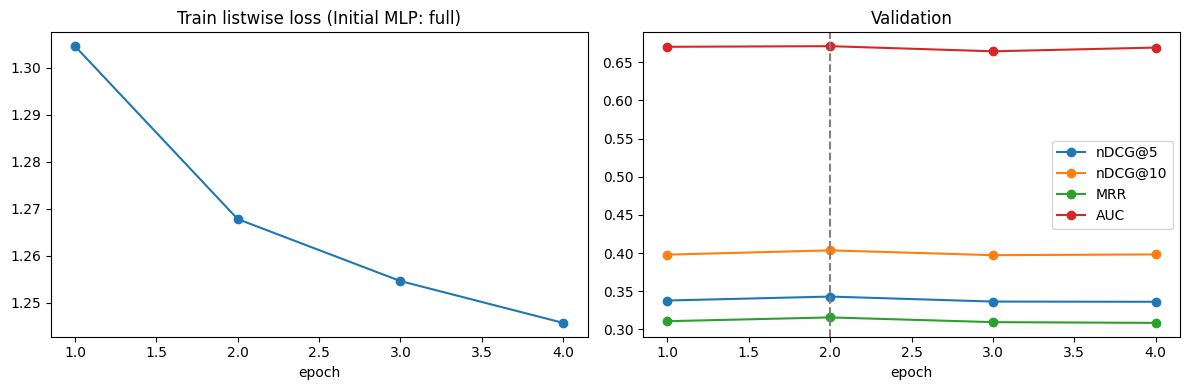

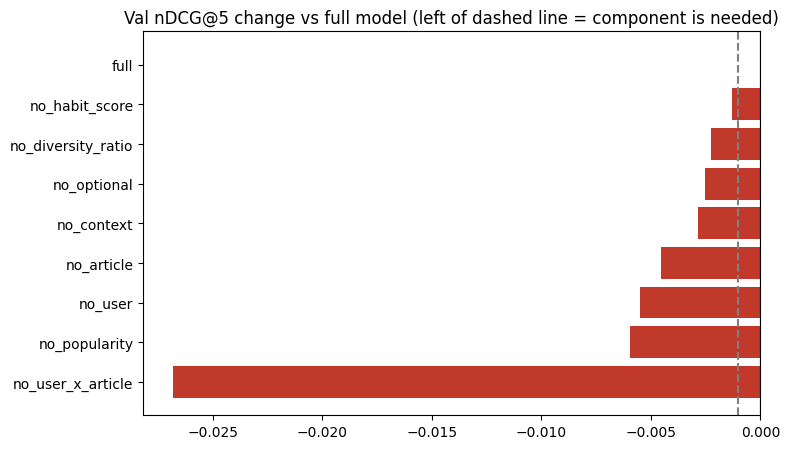

In [14]:
plot_training_and_ablation(hist1, best_ep1, f"Initial MLP: {BEST1}", ablation1)

### 1.4 Validation results by user group
Compared with popularity CTR (lagged `hist_ctr` only) and random scores on the same validation slates. The `margin over popularity` row shows how much the MLP adds beyond popularity for each user group.

In [15]:
val1 = record_val("initial_mlp", predict(model1, A["val"]))
write_outputs(A["val"], VAL_SCORES["initial_mlp"], S1_OUT, tag="val")
val1.to_csv(os.path.join(S1_OUT, "val_metrics.csv"), index=False)
print("Initial MLP, validation (all metrics):")
print(val1.to_string(index=False))

cmp1 = val_pivot(["popularity_ctr", "random", "initial_mlp"])
cmp1["margin over popularity"] = cmp1["initial_mlp"] - cmp1["popularity_ctr"]
print("\nValidation nDCG@5 by user group:")
print(cmp1.to_string())
cmp1.to_csv(os.path.join(S1_OUT, "val_vs_baselines.csv"))

Initial MLP, validation (all metrics):
       slice  n_impressions  n_users    AUC    MRR  nDCG@5  nDCG@10  Recall@5  Recall@10
         all          30270    20179 0.6710 0.3157  0.3430   0.4036    0.4690     0.6418
   cold_user            772      476 0.5742 0.2353  0.2516   0.3064    0.3776     0.5363
 sparse_user           3247     2657 0.6073 0.2972  0.3128   0.3728    0.4510     0.6280
   warm_user          26251    17046 0.6818 0.3204  0.3495   0.4102    0.4739     0.6466
cold_article          22543    16161 0.6611 0.3316  0.3577   0.4149    0.4942     0.6602

Validation nDCG@5 by user group:
              popularity_ctr  random  initial_mlp  margin over popularity
slice                                                                    
all                   0.2420  0.2015       0.3430                  0.1011
warm_user             0.2382  0.1982       0.3495                  0.1112
sparse_user           0.2720  0.2299       0.3128                  0.0408
cold_user             0

### 1.5 Diagnosis: why cold users gain least
The checks below quantify the explanation: cold users are a small share of training, and every cold user has the same user inputs, so the model rarely sees that input pattern.

In [16]:
tr = A["train"]
tr_cold = tr["hist_len"] == 0
print(f"Cold users in training: {tr_cold.mean():.2%} of training groups")
print(f"Distinct user profiles among cold training groups: {np.unique(tr['prof'][tr_cold]).size}")
print(
    f"Distinct user-scalar rows among cold training groups: "
    f"{np.unique(tr['user_x'][tr_cold].round(6), axis=0).shape[0]}"
)
print(
    "\nMargin over popularity (validation nDCG@5): "
    + ", ".join(f"{s} {cmp1.loc[s, 'margin over popularity']:+.4f}" for s in ["warm_user", "sparse_user", "cold_user"])
)

Cold users in training: 1.91% of training groups
Distinct user profiles among cold training groups: 1
Distinct user-scalar rows among cold training groups: 1

Margin over popularity (validation nDCG@5): warm_user +0.1112, sparse_user +0.0408, cold_user +0.0081


**Diagnosis.** The Initial MLP beats popularity by a wide margin for users with history, but adds very little for cold users, who are also its weakest group. Cold users are under 2% of training groups and all share one input pattern (profile 0, identical scalars and training-mean match features), so the model mostly applies weights learned from users with history, whose personal match features carry no information for a cold user. **Stage 2** therefore targets cold users.

## Stage 2: Improved MLP (cold-user simulation)
**Change.** In every training batch, each user with history is shown to the model as a cold user with probability `COLD_SIM_RATE` (15%): profile 0, the cold user scalars and the training-mean match features. Their real clicks stay as labels, so the model learns from real clicks what users without history choose. A new random draw is made every batch. Validation and test data are never altered.

### 2.1 Cold-user simulation inputs
The simulated inputs must equal what a real cold user receives; the check below confirms this.

In [17]:
COLD_PROFILE = 0  # profile 0 = empty history (feature engineering)
assert profiles.loc[COLD_PROFILE, "history_length"] == 0, "profile 0 must be the empty-history profile"
COLD_USER_X = user_x_all[COLD_PROFILE].copy()  # user scalars of a cold user (standardised)
COLD_INTER = np.array(
    [(meta["imputation_means"][c] - cand_mu[c]) / cand_sd[c] for c in INTER_COLS],
    np.float32,
)  # user x article values of a cold user (standardised)
tr = A["train"]
tr_cold = tr["hist_len"] == 0
if tr_cold.any():
    real_cold_rows = np.repeat(tr_cold, tr["n"])
    assert np.allclose(tr["cand_x"][real_cold_rows][:, len(POP_COLS) :], COLD_INTER, atol=1e-4)
    assert (
        np.allclose(tr["user_x"][tr_cold], COLD_USER_X, atol=1e-5)
        and (tr["prof"][tr_cold] == COLD_PROFILE).all()
    )
print("Simulated cold-user inputs match real cold-user inputs exactly.")
print(pd.Series(COLD_INTER, index=INTER_COLS).round(4).to_string())
print(f"\nReal cold users in training: {tr_cold.mean():.2%} of training groups")
print(
    f"With COLD_SIM_RATE = {COLD_SIM_RATE:.0%}: ~{tr_cold.mean() + COLD_SIM_RATE * (~tr_cold).mean():.1%} "
    "of training groups look cold to the model in each epoch"
)

Simulated cold-user inputs match real cold-user inputs exactly.
category_match    0.0000
cos_user_hist     0.0000
max_cos_hist     -0.0000
cos_last5         0.0000
cat_affinity     -0.0000
kg_match          0.0000

Real cold users in training: 1.91% of training groups
With COLD_SIM_RATE = 15%: ~16.6% of training groups look cold to the model in each epoch


### 2.2 Train (or reload) the full model with simulation

In [18]:
S2_RUN_DIR, S2_OUT = RUN_DIRS["improved"], REPORT_DIRS["stage2_improved"]
runs2 = {}
run_experiment(FULL_CFG, runs2, S2_RUN_DIR, verbose=True, cold_rate=COLD_SIM_RATE);

full                         seed 42 | cold sim 15% | best epoch 2 | val nDCG@5 0.3440 | reused saved run


### 2.3 Ablation and feature selection under simulation (validation)
The ablation is repeated because the best feature set can change once the model is trained differently. Every config here is trained with simulation.

In [19]:
if RUN_ABLATION:
    ablation2, BEST2 = run_ablation(FULL_CFG, runs2, S2_RUN_DIR, cold_rate=COLD_SIM_RATE)
    ablation2.to_csv(os.path.join(S2_OUT, "ablation.csv"), index=False)
else:
    ablation2, BEST2 = None, "full"

BEST2_CFG = runs2[BEST2]["cfg"]
print(f"\n>>> Stage 2 selected config: {BEST2}")
for block, cols in active_features(BEST2_CFG).items():
    print(f"  {block:15s}: {cols}")
model2, hist2, best_ep2 = load_selected(runs2, BEST2)
hist2.to_csv(os.path.join(S2_OUT, "training_history.csv"), index=False)
torch.save(model2.state_dict(), os.path.join(S2_OUT, "improved_mlp_best.pt"))

no_diversity_ratio           seed 42 | cold sim 15% | best epoch 2 | val nDCG@5 0.3385 | reused saved run
no_habit_score               seed 42 | cold sim 15% | best epoch 2 | val nDCG@5 0.3385 | reused saved run
no_optional                  seed 42 | cold sim 15% | best epoch 2 | val nDCG@5 0.3450 | reused saved run
no_article                   seed 42 | cold sim 15% | best epoch 2 | val nDCG@5 0.3389 | reused saved run
no_popularity                seed 42 | cold sim 15% | best epoch 5 | val nDCG@5 0.3330 | reused saved run
no_user                      seed 42 | cold sim 15% | best epoch 2 | val nDCG@5 0.3354 | reused saved run
no_user_x_article            seed 42 | cold sim 15% | best epoch 7 | val nDCG@5 0.3194 | reused saved run
no_context                   seed 42 | cold sim 15% | best epoch 2 | val nDCG@5 0.3410 | reused saved run

Ablation (validation; delta = config - full; "drop" = removing it does not hurt):
            config                       removed  val_AUC  val_MRR  v

### 2.4 Training curves and ablation chart

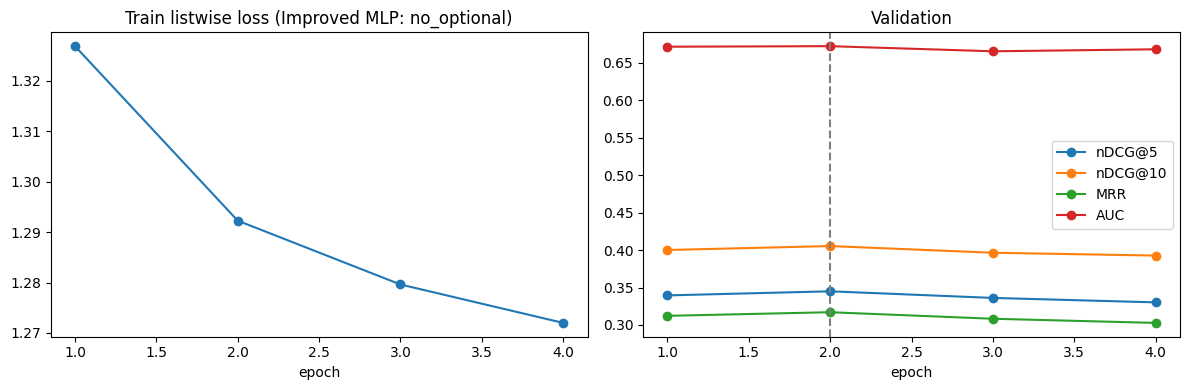

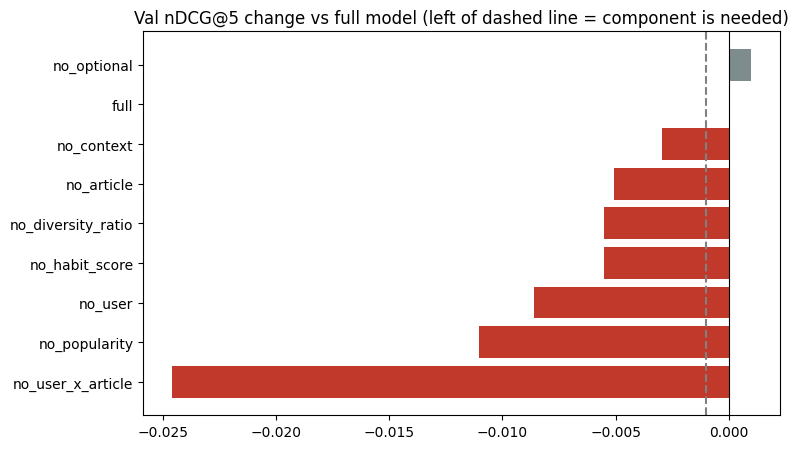

In [20]:
plot_training_and_ablation(hist2, best_ep2, f"Improved MLP: {BEST2}", ablation2)

### 2.5 Validation results by user group
The Improved MLP is compared with the Initial MLP selected in Stage 1 and with popularity CTR, on the same validation slates. Between the two stages, cold-user simulation was added and the Stage 2 ablation dropped `diversity_ratio` and `habit_score`, so the difference reflects both changes.

In [21]:
val2 = record_val("improved_mlp", predict(model2, A["val"]))
write_outputs(A["val"], VAL_SCORES["improved_mlp"], S2_OUT, tag="val")
val2.to_csv(os.path.join(S2_OUT, "val_metrics.csv"), index=False)
print("Improved MLP, validation (all metrics):")
print(val2.to_string(index=False))

compare_names = ["popularity_ctr", "initial_mlp", "improved_mlp"]
cmp2 = val_pivot(compare_names)
cmp2["improved_mlp - initial_mlp"] = cmp2["improved_mlp"] - cmp2["initial_mlp"]
cmp2["margin over popularity"] = cmp2["improved_mlp"] - cmp2["popularity_ctr"]
print("\nValidation nDCG@5 by user group:")
print(cmp2.to_string())
cmp2.to_csv(os.path.join(S2_OUT, "val_vs_stage1.csv"))

Improved MLP, validation (all metrics):
       slice  n_impressions  n_users    AUC    MRR  nDCG@5  nDCG@10  Recall@5  Recall@10
         all          30270    20179 0.6723 0.3170  0.3450   0.4054    0.4718     0.6441
   cold_user            772      476 0.5842 0.2507  0.2644   0.3189    0.3814     0.5381
 sparse_user           3247     2657 0.6083 0.3017  0.3175   0.3780    0.4540     0.6328
   warm_user          26251    17046 0.6828 0.3209  0.3507   0.4113    0.4767     0.6486
cold_article          22543    16161 0.6643 0.3322  0.3594   0.4168    0.4988     0.6647

Validation nDCG@5 by user group:
              popularity_ctr  initial_mlp  improved_mlp  improved_mlp - initial_mlp  margin over popularity
slice                                                                                                      
all                   0.2420       0.3430        0.3450                      0.0019                  0.1030
warm_user             0.2382       0.3495        0.3507             

### 2.6 Is a popularity fallback for cold users still needed? (validation)
A rule that ranks cold users by popularity is only worth adding if popularity beats the model on validation cold users.

In [22]:
cold_val = val_pivot(["popularity_ctr", "improved_mlp"]).loc["cold_user"]
NEED_FALLBACK = bool(cold_val["popularity_ctr"] > cold_val["improved_mlp"])
print(
    f"Validation, cold users: improved {cold_val['improved_mlp']:.4f} vs popularity {cold_val['popularity_ctr']:.4f} "
    f"-> popularity fallback {'needed' if NEED_FALLBACK else 'not needed'}"
)

Validation, cold users: improved 0.2644 vs popularity 0.2435 -> popularity fallback not needed


### 2.7 Diagnosis: what remains for users with history
In the Improved MLP, every user with history is represented by one mean vector of their clicked articles, the same for every candidate. Users read broadly: the mean `reading_entropy` across users is **1.43** (see Section 10 of `1_eda`), equivalent to reading about four categories equally (e^1.43 ≈ 4.2).

The cell below shows how much each user group changed from the Initial MLP to the Improved MLP on validation.

In [23]:
change = cmp2.loc[["warm_user", "sparse_user", "cold_user"], ["initial_mlp", "improved_mlp", "improved_mlp - initial_mlp"]]
change.columns = ["Initial MLP", "Improved MLP", "Change"]
print("Validation nDCG@5, Initial MLP -> Improved MLP:")
print(change.to_string())

Validation nDCG@5, Initial MLP -> Improved MLP:
             Initial MLP  Improved MLP  Change
slice                                         
warm_user         0.3495        0.3507  0.0013
sparse_user       0.3128        0.3175  0.0047
cold_user         0.2516        0.2644  0.0128


**Diagnosis.** Cold-user simulation fixes the cold-user weakness without hurting the other groups, but warm users, who make up most impressions, barely change. Their representation is a single average of their clicks, used unchanged for every candidate. Since users read across about four categories, this average blurs distinct interests into one profile that matches none of their interests well: a user who reads both sports and finance gets a profile halfway between the two, which fits neither a sports nor a finance article strongly. **Stage 3** therefore makes the user representation depend on the candidate.

## Stage 3: Attention MLP
**Change.** An additional attention block scores each of the user's last 50 clicks against the candidate and adds the weighted sum of clicks as an extra input block. The Stage 2 features and cold-user simulation are unchanged, so attention is the only design difference.

### 3.1 Configuration and click histories
The attention model is built on the Stage 2 selected config. Its saved run was trained with `diversity_ratio` and `habit_score` dropped, so the check below confirms Stage 2 selected the same features.

In [24]:
S3_RUN_DIR, S3_OUT = RUN_DIRS["attention"], REPORT_DIRS["stage3_attention"]
CFG3 = BEST2_CFG
SAVED_ATTENTION_DROP = ["diversity_ratio", "habit_score"]  # features of the saved attention run
assert CFG3["drop"] == sorted(SAVED_ATTENTION_DROP) and all(CFG3["groups"].values()), (
    "Stage 2 selected a different feature set than the saved attention run: "
    "delete the saved run in RUN_DIRS['attention'] to retrain it"
)
for block, cols in active_features(CFG3).items():
    print(f"{block:15s}: {cols}")

HIST = np.load(Path(FEATURE_DIR) / "user_history_indices.npy")  # [profiles, 50], 0 = empty slot
assert HIST.shape == (len(profiles), HIST_LEN)
assert (HIST[COLD_PROFILE] == 0).all()  # cold users (and simulated cold users) have no clicks

news_raw = load_preprocessed(PATHS)[1].set_index("news_id")


def describe(n):
    """'[category] title' for an article number."""
    row = news_raw.loc[news_ids[n]]
    return f"[{row['category']}] {str(row['title'])[:70]}"


example_prof = A["train"]["prof"][np.argmax(A["train"]["hist_len"] >= 20)]
clicks = HIST[example_prof][HIST[example_prof] > 0]
print(f"\nProfile {example_prof}: {len(clicks)} clicks in the window. Last 5:")
for n in clicks[-5:]:
    print("  ", describe(n))

popularity     : ['hist_ctr', 'log_exposure', 'is_cold_article']
user_x_article : ['category_match', 'cos_user_hist', 'max_cos_hist', 'cos_last5', 'cat_affinity', 'kg_match']
user           : ['log_history_length', 'has_history', 'reading_entropy']
context        : ['hour_sin', 'hour_cos']

Profile 2: 50 clicks in the window. Last 5:
   [news] Air Force airman missing after fall into Gulf of Mexico from C-130 air
   [news] Gunmen kill 15 in southern Thailand's worst attack in years
   [lifestyle] Dad thought he dressed toddler daughter in a hat, but he was hilarious
   [travel] This $12 million 'mansion yacht' is made entirely of stainless steel  
   [music] Dean Martin's Daughter Speaks Out About John Legend's New Version of '


### 3.2 The attention block
For one candidate `q` and each past click `k` (both encoded as 64-d article vectors):
1. **Score each click** with a small learned network: `score(q, k) = w · ReLU(W_q q + W_k k + W_p (q × k) + b)`. The element-wise `q × k` term is large when the two articles share features.
2. **Turn scores into weights** with a softmax over the user's clicks; padded slots get weight 0.
3. **Weighted sum**: the user vector for this candidate = Σ weight × click vector.

A user with no clicks gets all-zero weights, so the block is a constant for every candidate.

In [25]:
class ClickAttention(nn.Module):
    """Candidate-aware attention over a user's past clicks (DIN-style scoring unit)."""

    def __init__(self, d, hidden):
        super().__init__()
        self.w_q = nn.Linear(d, hidden)  # looks at the candidate
        self.w_k = nn.Linear(d, hidden, bias=False)  # looks at the past click
        self.w_p = nn.Linear(d, hidden, bias=False)  # looks at candidate x click
        self.out = nn.Linear(hidden, 1)  # -> one relevance score

    def forward(self, q, k, valid):
        """q: [batch, n_candidates, d]; k: [batch, n_clicks, d]; valid: [batch, n_clicks]."""
        q4, k4 = q.unsqueeze(2), k.unsqueeze(1)
        hidden = torch.relu(self.w_q(q4) + self.w_k(k4) + self.w_p(q4 * k4))
        scores = self.out(hidden).squeeze(-1)  # [batch, n_candidates, n_clicks]
        valid = valid.unsqueeze(1)
        scores = scores.masked_fill(~valid, -1e4)  # padding -> very low score
        weights = torch.softmax(scores, dim=-1) * valid  # add up to 1; no clicks -> all 0
        return weights @ k, weights


# mechanics check on toy numbers: 3 real clicks + 2 padded slots, 2 candidates
torch.manual_seed(0)
toy = ClickAttention(d=8, hidden=4)
_, w = toy(torch.randn(1, 2, 8), torch.randn(1, 5, 8), torch.tensor([[True, True, True, False, False]]))
print("weights (rows = candidates, columns = clicks):")
print(w[0].detach().numpy().round(3))
print("row sums:", w[0].sum(-1).detach().numpy().round(3))

weights (rows = candidates, columns = clicks):
[[0.325 0.388 0.287 0.    0.   ]
 [0.34  0.338 0.322 0.    0.   ]]
row sums: [1. 1.]


### 3.3 Improved MLP + attention
Every article (the candidate and each past click) is encoded with the Improved MLP's own text and category projections (`text block + category block`), so candidates and clicks are comparable. The attended vector goes through a `Proj` like every other block and is added as one more block (576 → 640 inputs to the scoring MLP).

In [26]:
class MLPWithAttention(MLPRanker):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.register_buffer("hist", torch.as_tensor(HIST), persistent=False)  # click list per profile
        self.attention = ClickAttention(EMBED_DIM, ATT_HIDDEN)
        self.user_attn_proj = Proj(EMBED_DIM, EMBED_DIM)
        self.mlp = make_head((self.n_blocks + 1) * EMBED_DIM)  # one more block

    def encode_article(self, news):
        """Article -> 64 numbers, using the text and category projections."""
        cat = torch.cat(
            [self.cat_emb(self.art_cat[news]), self.subcat_emb(self.art_subcat[news])], -1
        )
        return self.text_proj(self.content_emb[news]) + self.cat_proj(cat)

    def click_weights(self, news, prof):
        """Attention weights for candidates `news` and user profiles `prof`."""
        clicks = self.hist[prof]
        _, w = self.attention(self.encode_article(news), self.encode_article(clicks), clicks > 0)
        return w

    def forward(self, news, mask, cand_x, prof, user_x, ctx_x):
        b = self.blocks(news, cand_x, prof, user_x, ctx_x)
        clicks = self.hist[prof]  # [batch, 50] past clicks
        q = b["text"] + b["cat"]  # the candidates, encoded
        k = self.encode_article(clicks)  # the clicks, encoded the same way
        user_vec, _ = self.attention(q, k, clicks > 0)
        b["user_attn"] = self.user_attn_proj(user_vec)
        score = self.mlp(torch.cat(list(b.values()), -1)).squeeze(-1)
        return score.masked_fill(~mask, float("-inf"))


def build_attention_model():
    return MLPWithAttention(CFG3).to(device)


n_params = {
    "improved": sum(p.numel() for p in model2.parameters()),
    "attention": sum(p.numel() for p in build_attention_model().parameters()),
}
print(
    f"Improved MLP : {n_params['improved']:>8,} parameters\n"
    f"Attention MLP: {n_params['attention']:>8,} parameters "
    f"(+{n_params['attention'] - n_params['improved']:,}, "
    f"+{(n_params['attention'] / n_params['improved'] - 1):.1%})"
)

Improved MLP :  157,633 parameters
Attention MLP:  176,322 parameters (+18,689, +11.9%)


### 3.4 Train (or reload) the attention model

In [27]:
def train_or_load_attention():
    settings = json.dumps(
        {
            "model": "mlp_attn",
            "feature_id": feature_id,
            "cat_dim": CAT_DIM,
            "subcat_dim": SUBCAT_DIM,
            "seed": SEED,
            "hidden": HIDDEN,
            "lr": LR,
            "epochs": MAX_EPOCHS,
            "cold_sim": COLD_SIM_RATE,
            "hist_len": HIST_LEN,
            "att_hidden": ATT_HIDDEN,
        },
        sort_keys=True,
    )
    weights, hist_csv, info = [os.path.join(S3_RUN_DIR, f"mlp_attn.{e}") for e in ["pt", "csv", "json"]]
    if all(os.path.exists(p) for p in [weights, hist_csv, info]) and open(info).read() == settings:
        model = build_attention_model()
        model.load_state_dict(torch.load(weights, map_location=device))
        print("mlp_attn: reloaded saved run")
        return model, pd.read_csv(hist_csv)
    print("Training mlp_attn")
    t0 = time.time()
    model, history = train_model(
        CFG3, cold_rate=COLD_SIM_RATE, builder=build_attention_model, max_rows=EVAL_ROWS
    )
    torch.save(model.state_dict(), weights)
    history.to_csv(hist_csv, index=False)
    open(info, "w").write(settings)
    print(f"mlp_attn: done in {(time.time() - t0) / 60:.1f} min")
    return model, history


attn_model, attn_hist = train_or_load_attention()
attn_hist.to_csv(os.path.join(S3_OUT, "training_history.csv"), index=False)

mlp_attn: reloaded saved run


### 3.5 Training curves: Improved MLP vs Attention MLP

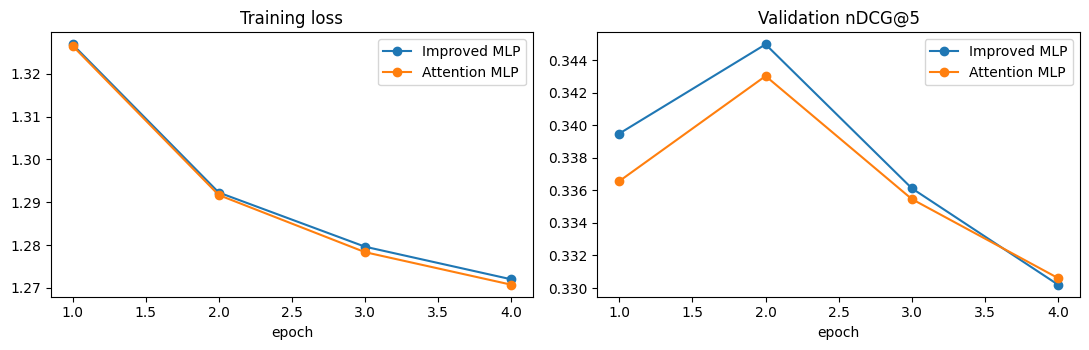

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, h in [("Improved MLP", hist2), ("Attention MLP", attn_hist)]:
    ax[0].plot(h.epoch, h.train_loss, marker="o", label=name)
    ax[1].plot(h.epoch, h["val_nDCG@5"], marker="o", label=name)
ax[0].set_title("Training loss")
ax[1].set_title("Validation nDCG@5")
for a in ax:
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()

### 3.6 Validation results by user group
A paired bootstrap resamples the validation impressions (the same ones for both models) 1,000 times; if the 95% interval of the difference excludes 0, the difference is unlikely to come from which impressions happen to be in the validation day. It does not cover training randomness (one seed).

In [29]:
val3 = record_val("attention_mlp", predict(attn_model, A["val"], max_rows=EVAL_ROWS))
val3.to_csv(os.path.join(S3_OUT, "val_metrics.csv"), index=False)
print("Attention MLP, validation (all metrics):")
print(val3.to_string(index=False))

cmp3 = val_pivot(["popularity_ctr", "improved_mlp", "attention_mlp"])
cmp3["attention_mlp - improved_mlp"] = cmp3["attention_mlp"] - cmp3["improved_mlp"]
print("\nValidation nDCG@5 by user group:")
print(cmp3.to_string())
cmp3.to_csv(os.path.join(S3_OUT, "val_vs_stage2.csv"))

rows = []
for g, mask in user_groups(A["val"]).items():
    a = VAL_PER_IMP["attention_mlp"]["nDCG@5"].values[mask]
    b = VAL_PER_IMP["improved_mlp"]["nDCG@5"].values[mask]
    mean, lo, hi = paired_bootstrap(a, b)
    rows.append({"users": g, "nDCG@5 difference": mean, "95% low": lo, "95% high": hi,
                 "excludes 0": not (lo <= 0 <= hi)})
boot3 = pd.DataFrame(rows)
print("\nAttention - Improved, paired bootstrap on validation:")
print(boot3.to_string(index=False))
boot3.to_csv(os.path.join(S3_OUT, "bootstrap_val.csv"), index=False)

Attention MLP, validation (all metrics):
       slice  n_impressions  n_users    AUC    MRR  nDCG@5  nDCG@10  Recall@5  Recall@10
         all          30270    20179 0.6729 0.3155  0.3430   0.4038    0.4694     0.6429
   cold_user            772      476 0.5820 0.2399  0.2530   0.3107    0.3737     0.5394
 sparse_user           3247     2657 0.6068 0.3011  0.3163   0.3772    0.4511     0.6310
   warm_user          26251    17046 0.6838 0.3195  0.3490   0.4098    0.4745     0.6474
cold_article          22543    16161 0.6638 0.3313  0.3571   0.4151    0.4931     0.6614

Validation nDCG@5 by user group:
              popularity_ctr  improved_mlp  attention_mlp  attention_mlp - improved_mlp
slice                                                                                  
all                   0.2420        0.3450         0.3430                       -0.0019
warm_user             0.2382        0.3507         0.3490                       -0.0018
sparse_user           0.2720        0.3

### 3.7 Where does attention help or hurt? (validation)
By number of past clicks, and, for warm users, by reading diversity (three equal groups by `reading_entropy`). If attention separates mixed interests, its effect should be more positive for broad readers.

                   nDCG5_change  impressions
clicks in history                           
0                       -0.0114          772
1-4                     -0.0012         3247
5-9                     -0.0064         4809
10-19                    0.0004         6266
20-49                   -0.0009         8990
50+                     -0.0017         6186


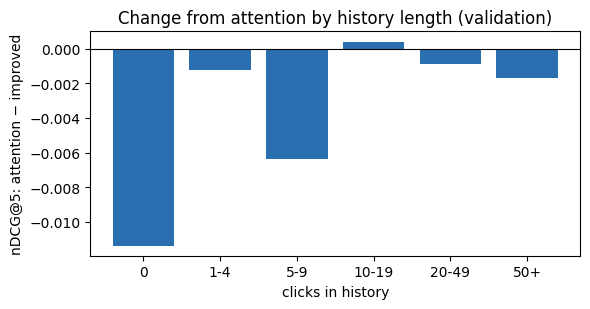


Warm validation users by reading diversity:
                   mean_entropy  nDCG5_change  impressions
reading diversity                                         
low diversity            1.1804       -0.0023         8750
medium                   1.7058       -0.0016         8750
high diversity           2.0494       -0.0013         8751


In [35]:
gain = VAL_PER_IMP["attention_mlp"]["nDCG@5"].values - VAL_PER_IMP["improved_mlp"]["nDCG@5"].values
buckets = pd.cut(
    A["val"]["hist_len"], [-1, 0, 4, 9, 19, 49, np.inf], labels=["0", "1-4", "5-9", "10-19", "20-49", "50+"]
)
by_length = (
    pd.DataFrame({"clicks in history": buckets, "gain": gain})
    .groupby("clicks in history", observed=False)["gain"]
    .agg(nDCG5_change="mean", impressions="size")
)
print(by_length.to_string())
by_length.to_csv(os.path.join(S3_OUT, "change_by_history_val.csv"))
plt.figure(figsize=(6, 3.2))
plt.bar(by_length.index.astype(str), by_length["nDCG5_change"], color="#2a6fb0")
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("clicks in history")
plt.ylabel("nDCG@5: attention − improved")
plt.title("Change from attention by history length (validation)")
plt.tight_layout()
plt.show()

Av = A["val"]
warm = Av["hist_len"] >= SPARSE_MAX
entropy = profiles["reading_entropy"].values[Av["prof"]][warm]
third = pd.qcut(pd.Series(entropy).rank(method="first"), 3, labels=["low diversity", "medium", "high diversity"])
by_diversity = (
    pd.DataFrame({"reading diversity": third.values, "entropy": entropy, "gain": gain[warm]})
    .groupby("reading diversity", observed=False)
    .agg(mean_entropy=("entropy", "mean"), nDCG5_change=("gain", "mean"), impressions=("gain", "size"))
)
print("\nWarm validation users by reading diversity:")
print(by_diversity.to_string())
by_diversity.to_csv(os.path.join(S3_OUT, "change_by_diversity_val.csv"))

### 3.8 One user, two candidates (validation)
A validation user who reads at least 3 categories, and two candidates from different categories in the same impression. For each candidate, the three past clicks with the highest attention weight. If attention works as intended, the top clicks change with the candidate.

In [36]:
rng = np.random.default_rng(SEED)
example = None
for g in rng.permutation(len(Av["n"])):
    clicks = HIST[Av["prof"][g]]
    clicks = clicks[clicks > 0]
    if len(clicks) < 10 or len(np.unique(art_cat[clicks])) < 3:
        continue
    s, k = Av["start"][g], Av["n"][g]
    pick = []
    for c in Av["news"][s : s + k]:
        if art_cat[c] in set(art_cat[clicks]) and art_cat[c] not in [art_cat[x] for x in pick]:
            pick.append(c)
        if len(pick) == 2:
            example = (g, pick, clicks)
            break
    if example:
        break

if example is None:
    print("No suitable example found")
else:
    g, pick, clicks = example
    attn_model.eval()
    with torch.no_grad():
        w = (
            attn_model.click_weights(
                torch.as_tensor([pick], device=device), torch.as_tensor([Av["prof"][g]], device=device)
            )[0]
            .cpu()
            .numpy()[:, : len(clicks)]
        )
    mix = pd.Series([news_raw.loc[news_ids[n], "category"] for n in clicks]).value_counts().to_dict()
    print(f"User {Av['user_id'][g]}: {len(clicks)} clicks, categories {mix}\n")
    for j, c in enumerate(pick):
        print("Candidate:", describe(c))
        for i in np.argsort(-w[j])[:3]:
            print(f"   weight {w[j, i]:.3f}  {describe(clicks[i])}")
        print(f"   (equal weighting would give {1 / len(clicks):.3f} each)\n")

User U86947: 28 clicks, categories {'news': 14, 'lifestyle': 3, 'music': 3, 'autos': 2, 'video': 2, 'sports': 2, 'weather': 2}

Candidate: [news] University of Florida student president faces impeachment for Trump Jr
   weight 0.187  [news] Joe Biden reportedly denied Communion at a South Carolina church becau
   weight 0.112  [news] Failed operation underlines Mexico chaos
   weight 0.072  [news] Texas police officer shoots woman to death inside her home
   (equal weighting would give 0.036 each)

Candidate: [weather] Nor'easter to grind at US East Coast this weekend
   weight 0.239  [sports] Aspen Ladd's suspension for scary weight cut lifted after showing focu
   weight 0.239  [sports] Aspen Ladd's suspension for scary weight cut lifted after showing focu
   weight 0.135  [music] A Detailed List of Gwen Stefani and Blake Shelton's Cutest Moments
   (equal weighting would give 0.036 each)



**Diagnosis.** On validation, attention does not improve on the Improved MLP. Cold users lose the most: they have no clicks to attend to, so the extra block adds parameters without information for them. For users with history, the changes are small and within single-seed noise; attention likely overlaps with `max_cos_hist` and `cos_last5`, which already pick out the closest and most recent clicks. Attention is therefore **not** carried forward.

## Stage 4: Final model selection and test evaluation
**Rule.** The final model is the MLP with the highest **validation** nDCG@5 over all users. Its per-group validation results are checked as well. Only after selection is the test day used, and only for the selected model, so the test results are an unbiased estimate of how it performs on unseen data.

### 4.1 Selection on validation

Validation nDCG@5:
             Popularity  Initial MLP  Improved MLP  Attention MLP
slice                                                            
all              0.2420       0.3430        0.3450         0.3430
warm_user        0.2382       0.3495        0.3507         0.3490
sparse_user      0.2720       0.3128        0.3175         0.3163
cold_user        0.2435       0.2516        0.2644         0.2530

Selected on validation: Improved MLP
Best MLP per user group: {'all': 'Improved MLP', 'warm_user': 'Improved MLP', 'sparse_user': 'Improved MLP', 'cold_user': 'Improved MLP'}


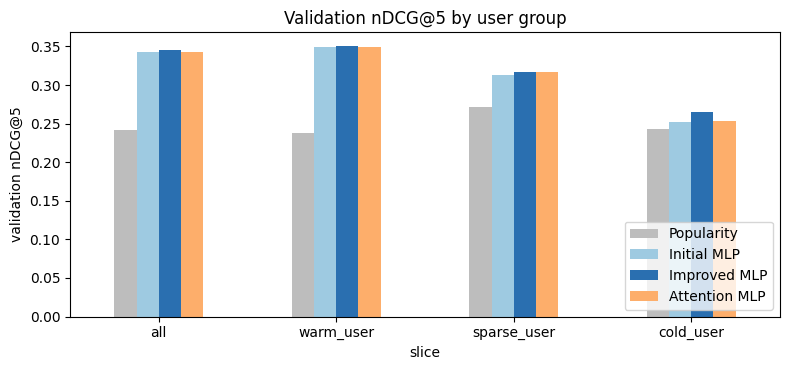

In [37]:
S4_OUT = REPORT_DIRS["stage4_final"]
CANDIDATES = {"initial_mlp": "Initial MLP", "improved_mlp": "Improved MLP", "attention_mlp": "Attention MLP"}
selection = val_pivot(["popularity_ctr"] + list(CANDIDATES)).loc[["all", "warm_user", "sparse_user", "cold_user"]]
selection = selection.rename(columns={"popularity_ctr": "Popularity", **CANDIDATES})
print("Validation nDCG@5:")
print(selection.to_string())
selection.to_csv(os.path.join(S4_OUT, "selection_val_ndcg5.csv"))

FINAL = selection.loc["all", list(CANDIDATES.values())].idxmax()
FINAL_KEY = {v: k for k, v in CANDIDATES.items()}[FINAL]
best_per_group = selection[list(CANDIDATES.values())].idxmax(axis=1)
print(f"\nSelected on validation: {FINAL}")
print("Best MLP per user group:", best_per_group.to_dict())

ax = selection.plot.bar(figsize=(8, 3.8), rot=0, color=["#bdbdbd", "#9ecae1", "#2a6fb0", "#fdae6b"])
ax.set_ylabel("validation nDCG@5")
ax.set_title("Validation nDCG@5 by user group")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.2 Cold-user fallback check (validation)
A popularity fallback for cold users is applied only if popularity beats the selected model on validation cold users.

In [38]:
USE_FALLBACK = bool(VAL_TABLES["popularity_ctr"].set_index("slice").loc["cold_user", "nDCG@5"]
                    > VAL_TABLES[FINAL_KEY].set_index("slice").loc["cold_user", "nDCG@5"])
print(f"Popularity fallback for cold users: {'ON' if USE_FALLBACK else 'OFF'}")

Popularity fallback for cold users: OFF


### 4.3 Test results of the selected model
This is the only place the test day is used.

In [40]:
FINAL_MODELS = {
    "initial_mlp": (model1, None),
    "improved_mlp": (model2, None),
    "attention_mlp": (attn_model, EVAL_ROWS),
}
final_model, final_rows = FINAL_MODELS[FINAL_KEY]
At = A["test"]
test_scores = predict(final_model, At, max_rows=final_rows)
if USE_FALLBACK:
    cold_rows = np.repeat(At["hist_len"] == 0, At["n"])
    test_scores = np.where(cold_rows, At["cand_x"][:, CTR_COL], test_scores)

test_table, _ = evaluate(At, test_scores)
test_table.insert(0, "model", FINAL + (" + fallback" if USE_FALLBACK else ""))
test_table.to_csv(os.path.join(S4_OUT, "test_metrics.csv"), index=False)
write_outputs(At, test_scores, S4_OUT, tag="test")
print(f"{FINAL}, test (15 Nov), full slates:")
print(test_table.set_index("slice").loc[SLICE_ORDER].to_string())

Improved MLP, test (15 Nov), full slates:
                     model  n_impressions  n_users    AUC    MRR  nDCG@5  nDCG@10  Recall@5  Recall@10
slice                                                                                                 
all           Improved MLP          73152    50000 0.6667 0.3253  0.3567   0.4193    0.4938     0.6723
warm_user     Improved MLP          62846    41986 0.6765 0.3267  0.3598   0.4225    0.4955     0.6738
sparse_user   Improved MLP           8092     6607 0.6185 0.3340  0.3552   0.4175    0.5035     0.6859
cold_user     Improved MLP           2214     1407 0.5631 0.2536  0.2752   0.3336    0.4103     0.5803
cold_article  Improved MLP          42682    32082 0.6786 0.3103  0.3360   0.3988    0.4831     0.6652


### 4.4 Save the final model and run configuration

In [41]:
torch.save(final_model.state_dict(), os.path.join(S4_OUT, "final_model.pt"))
final_cfg = {"initial_mlp": BEST1_CFG, "improved_mlp": BEST2_CFG, "attention_mlp": CFG3}[FINAL_KEY]
run_config = {
    "notebook": "6_mlp_staged",
    "final_model": FINAL,
    "selected_on": f"validation {SELECT_METRIC}",
    "cold_user_fallback": USE_FALLBACK,
    "stage_configs": {"initial": BEST1, "improved": BEST2, "attention": "improved config + attention"},
    "final_features": active_features(final_cfg),
    "dropped_features": final_cfg["drop"],
    "hyperparameters": {**HPARAMS, "seed": SEED},
    "cold_user_simulation": {"rate": COLD_SIM_RATE, "applies_to": "training batches, Stages 2-3"},
    "attention": {"hist_len": HIST_LEN, "att_hidden": ATT_HIDDEN},
    "validation_ndcg5": selection.to_dict(),
    "saved_runs": RUN_DIRS,
    "contract": {k: meta[k] for k in ["split", "negative_sampling", "cold_start", "leakage", "excluded_features"]},
}
with open(os.path.join(S4_OUT, "run_config.json"), "w") as f:
    json.dump(run_config, f, indent=2, default=str)
print("Outputs:", sorted(os.listdir(S4_OUT)))

Outputs: ['final_model.pt', 'prediction_test.txt', 'predictions_test.parquet', 'run_config.json', 'selection_val_ndcg5.csv', 'test_metrics.csv', 'topk_test.csv']


## Summary and limitations
* **Selection.** The final model is chosen on validation only; test results are reported once, for that model.
* **One training seed.** Differences of about ±0.002 nDCG@5 between configs can be run-to-run noise; the bootstrap covers sampling of impressions, not training randomness.
* **Attention window.** Attention sees only the last 50 clicks; older clicks reach the model only through the mean profile.
* **Data.** One validation day (14 Nov 2019) and one test day (15 Nov 2019) of MIND-small, a one-week sample of MSN News.